# Telco Customer Churn
**Sara Kamyar**

This notebook extends my class project into a reproducible comparison of churn models. I focus on ranking quality and the workload created by a recall-focused threshold. The dataset is a fictional IBM Telco sample; it does not establish a future prediction window or the effect of retention offers.

Run the cells in order from a fresh kernel. The experiment code lives in `src/churn.py`, so the notebook and command-line results use the same implementation.

## 1. Setup and data checks
The raw workbook stays outside version control. We require the expanded 33-column variant, check customer IDs and labels, and convert blank Total Charges entries to missing values.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd()
if not (ROOT / "src/churn.py").exists():
    ROOT = ROOT.parent
if not (ROOT / "src/churn.py").exists():
    raise RuntimeError("Open this notebook from the project root or notebooks folder.")
sys.path.insert(0, str(ROOT))
from src.churn import (FEATURES, load_data, split_data, train_models, choose_threshold,
    evaluate, create_figures, bootstrap_intervals)

data = load_data(ROOT / "data/raw/Telco_customer_churn.xlsx")
display(pd.DataFrame({"rows": [len(data)], "columns": [data.shape[1]],
    "missing_total_charges": [data["Total Charges"].isna().sum()],
    "churn_rate": [data["Churn Value"].mean()]}))
print("Allowed inputs:", FEATURES)

,rows,columns,missing_total_charges,churn_rate
0,7043,33,11,0.26537


Allowed inputs: ['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method', 'Monthly Charges', 'Total Charges']


## 2. Split before exploring or fitting
The test set is held aside. Training data supports EDA and cross-validation. Validation data selects the threshold. Imputation and encoding are fitted inside the pipelines. Churn Score is another model's output and CLTV has unverified timing, so both are excluded.

In [2]:
splits = split_data(data)
X_train, X_val, X_test, y_train, y_val, y_test = splits
display(pd.DataFrame([{"split": name, "rows": len(y), "churn_rate": y.mean()}
    for name, y in [("training", y_train), ("validation", y_val), ("test", y_test)]]))
training_data = data.loc[X_train.index]
display(training_data.groupby("Contract")["Churn Value"].agg(["count", "mean"]))

,split,rows,churn_rate
0,training,4225,0.265325
1,validation,1409,0.265436
2,test,1409,0.265436


,count,mean
Contract,,
Month-to-month,2326,0.430782
One year,865,0.107514
Two year,1034,0.025145


## 3. Compare the models
A majority baseline checks what accuracy means under imbalance. Logistic regression provides a simpler comparison. Random forest searches six parameter settings. Model family selection uses three-fold training average precision, which measures ranking of the churn class.

In [3]:
models, cv_results, selected, rf_parameters = train_models(X_train, y_train)
display(cv_results)
print("Selected model:", selected)
print("Random forest parameters:", rf_parameters)

,model,cv_average_precision,fold_std
2,Random forest,0.689068,0.005565
1,Logistic regression,0.685036,0.006640
0,Majority baseline,0.265325,0.000300


Selected model: Random forest
Random forest parameters: {'model__max_depth': 12, 'model__min_samples_leaf': 8}


## 4. Choose a threshold using validation data
F2 emphasizes recall. This is an explicit example objective rather than an estimate of business profit. When F2 ties, the code chooses the higher threshold. The fitted model remains unchanged after this step.

In [4]:
validation_probabilities = models[selected].predict_proba(X_val)[:, 1]
threshold, threshold_results = choose_threshold(y_val, validation_probabilities)
print(f"Validation-selected threshold: {threshold:.2f}")
display(threshold_results.sort_values(["f2", "threshold"], ascending=False).head(5))

Validation-selected threshold: 0.29


,threshold,precision,recall,f2,contact_rate
24,0.29,0.436409,0.935829,0.761532,0.569198
23,0.28,0.430845,0.941176,0.760917,0.579844
27,0.32,0.448501,0.919786,0.760053,0.544358
25,0.30,0.439797,0.927807,0.759300,0.559972
26,0.31,0.443445,0.922460,0.758575,0.552165


## 5. Evaluate on the held-out test set
Model and threshold decisions are now frozen. Compare the 0.50 operating rule with the validation-selected rule. Lowering a threshold changes precision, recall and workload, but not ranking metrics.

In [5]:
test_results, probabilities = evaluate(models, selected, threshold, X_test, y_test)
display(test_results.round(4))
print("95% bootstrap intervals for fixed test predictions:")
display(bootstrap_intervals(y_test, probabilities[selected]))

,model,threshold,accuracy,precision,recall,f1,roc_auc,average_precision,brier_score,contact_rate
0,Majority baseline,0.50,0.7346,0.0000,0.0000,0.0000,0.5000,0.2654,0.1950,0.0000
1,Logistic regression,0.50,0.8048,0.6460,0.5856,0.6143,0.8495,0.6435,0.1357,0.2406
2,Random forest,0.50,0.7587,0.5308,0.7834,0.6328,0.8529,0.6576,0.1555,0.3918
3,Random forest (validation threshold),0.29,0.6678,0.4405,0.9305,0.5979,0.8529,0.6576,0.1555,0.5607


95% bootstrap intervals for fixed test predictions:


{'roc_auc': [0.8307453625799588, 0.8730745063180486],
 'average_precision': [0.6078129586962621, 0.7076975594088315]}

## 6. Inspect the figures
The first two figures use training data. Threshold curves use validation data. The remaining figures use test data. Permutation importance is descriptive and does not feed back into feature or model selection.

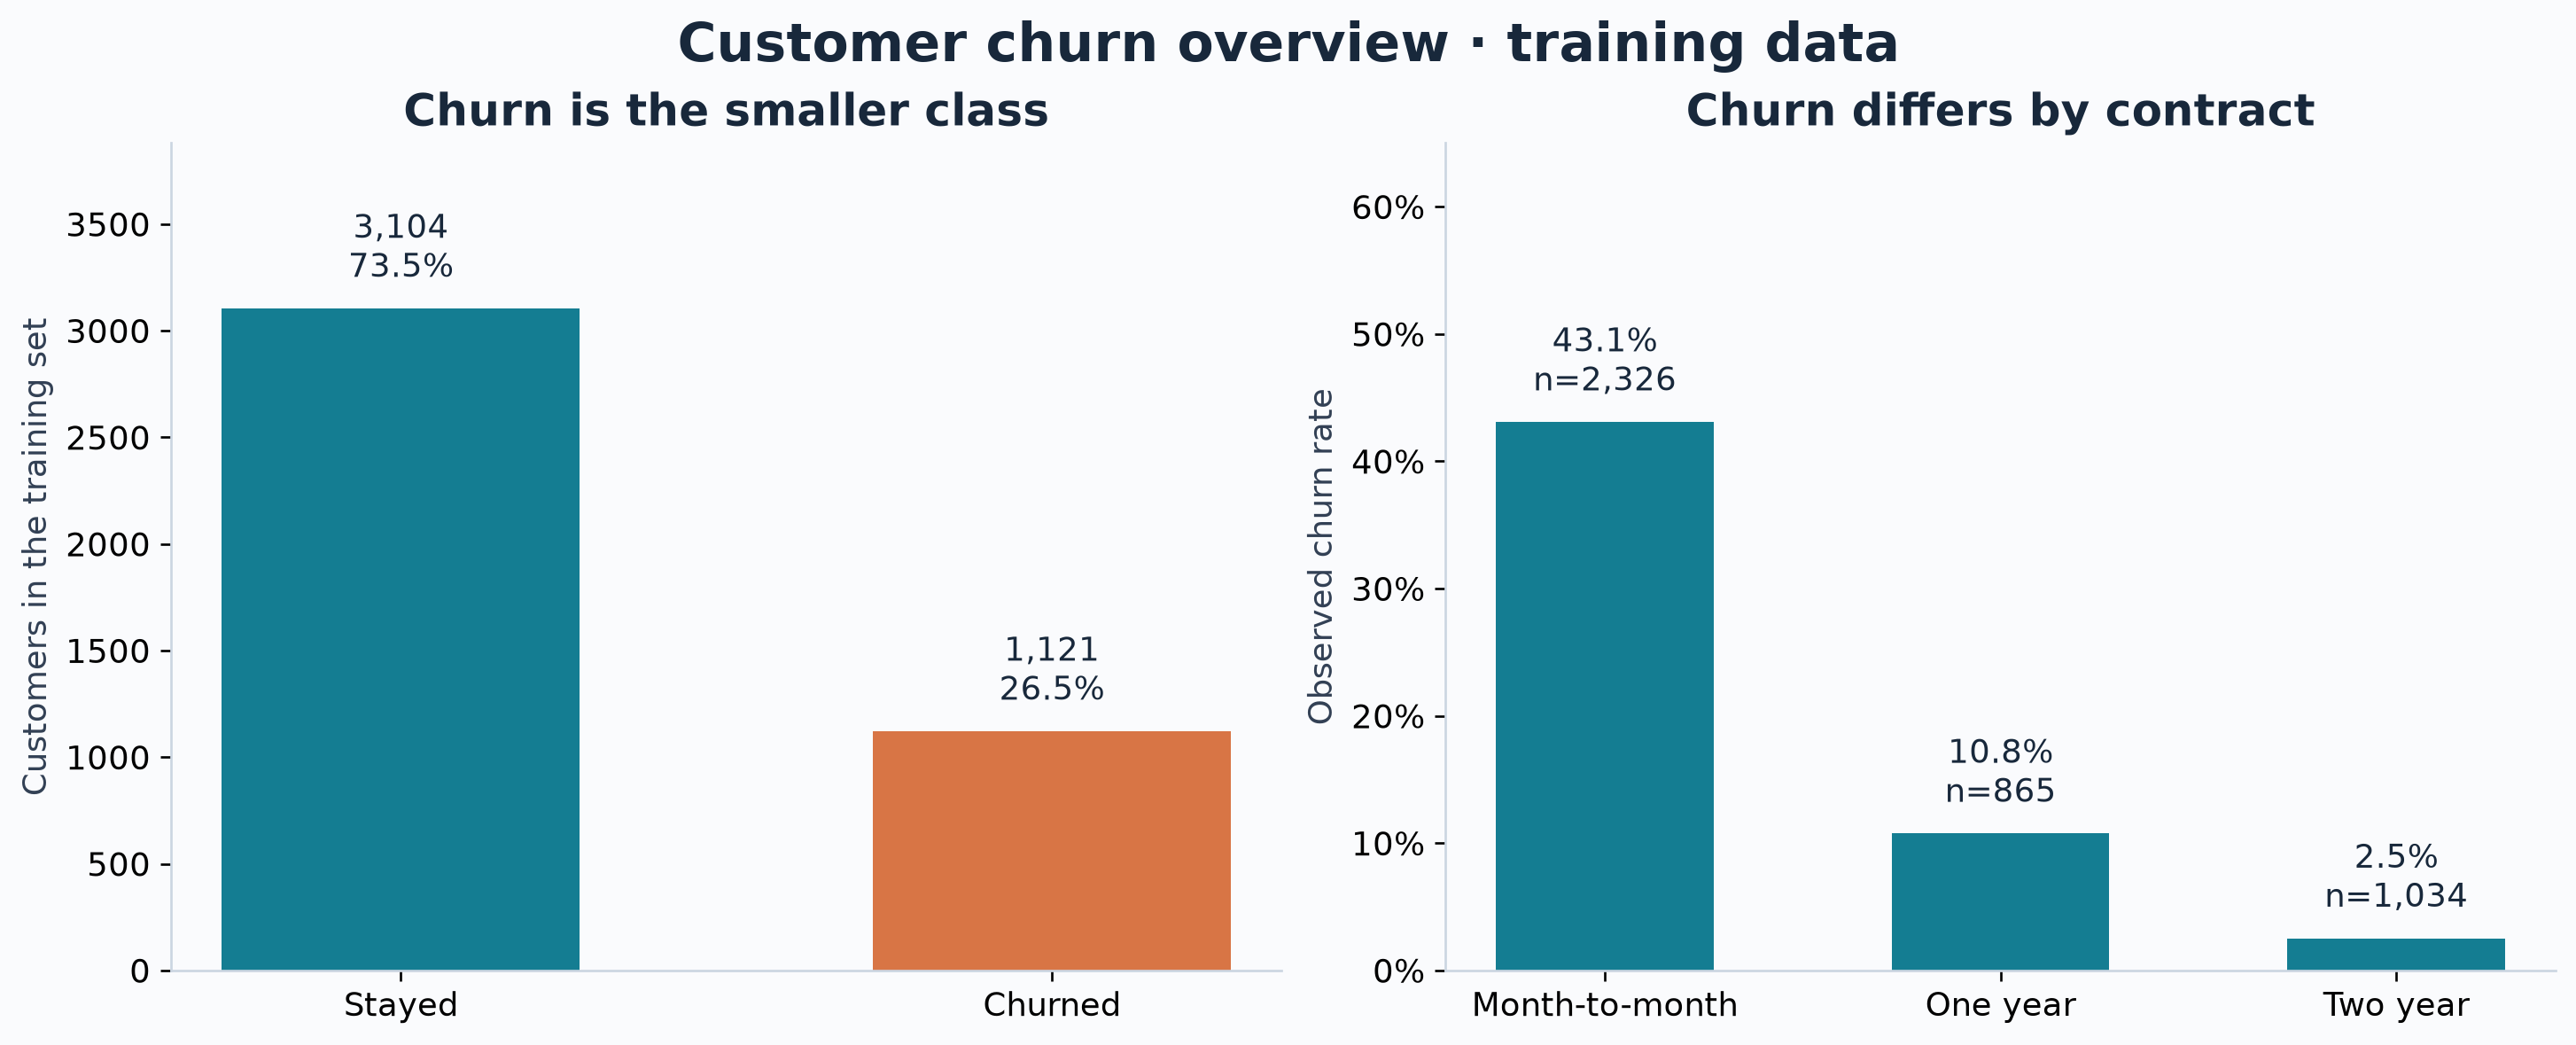

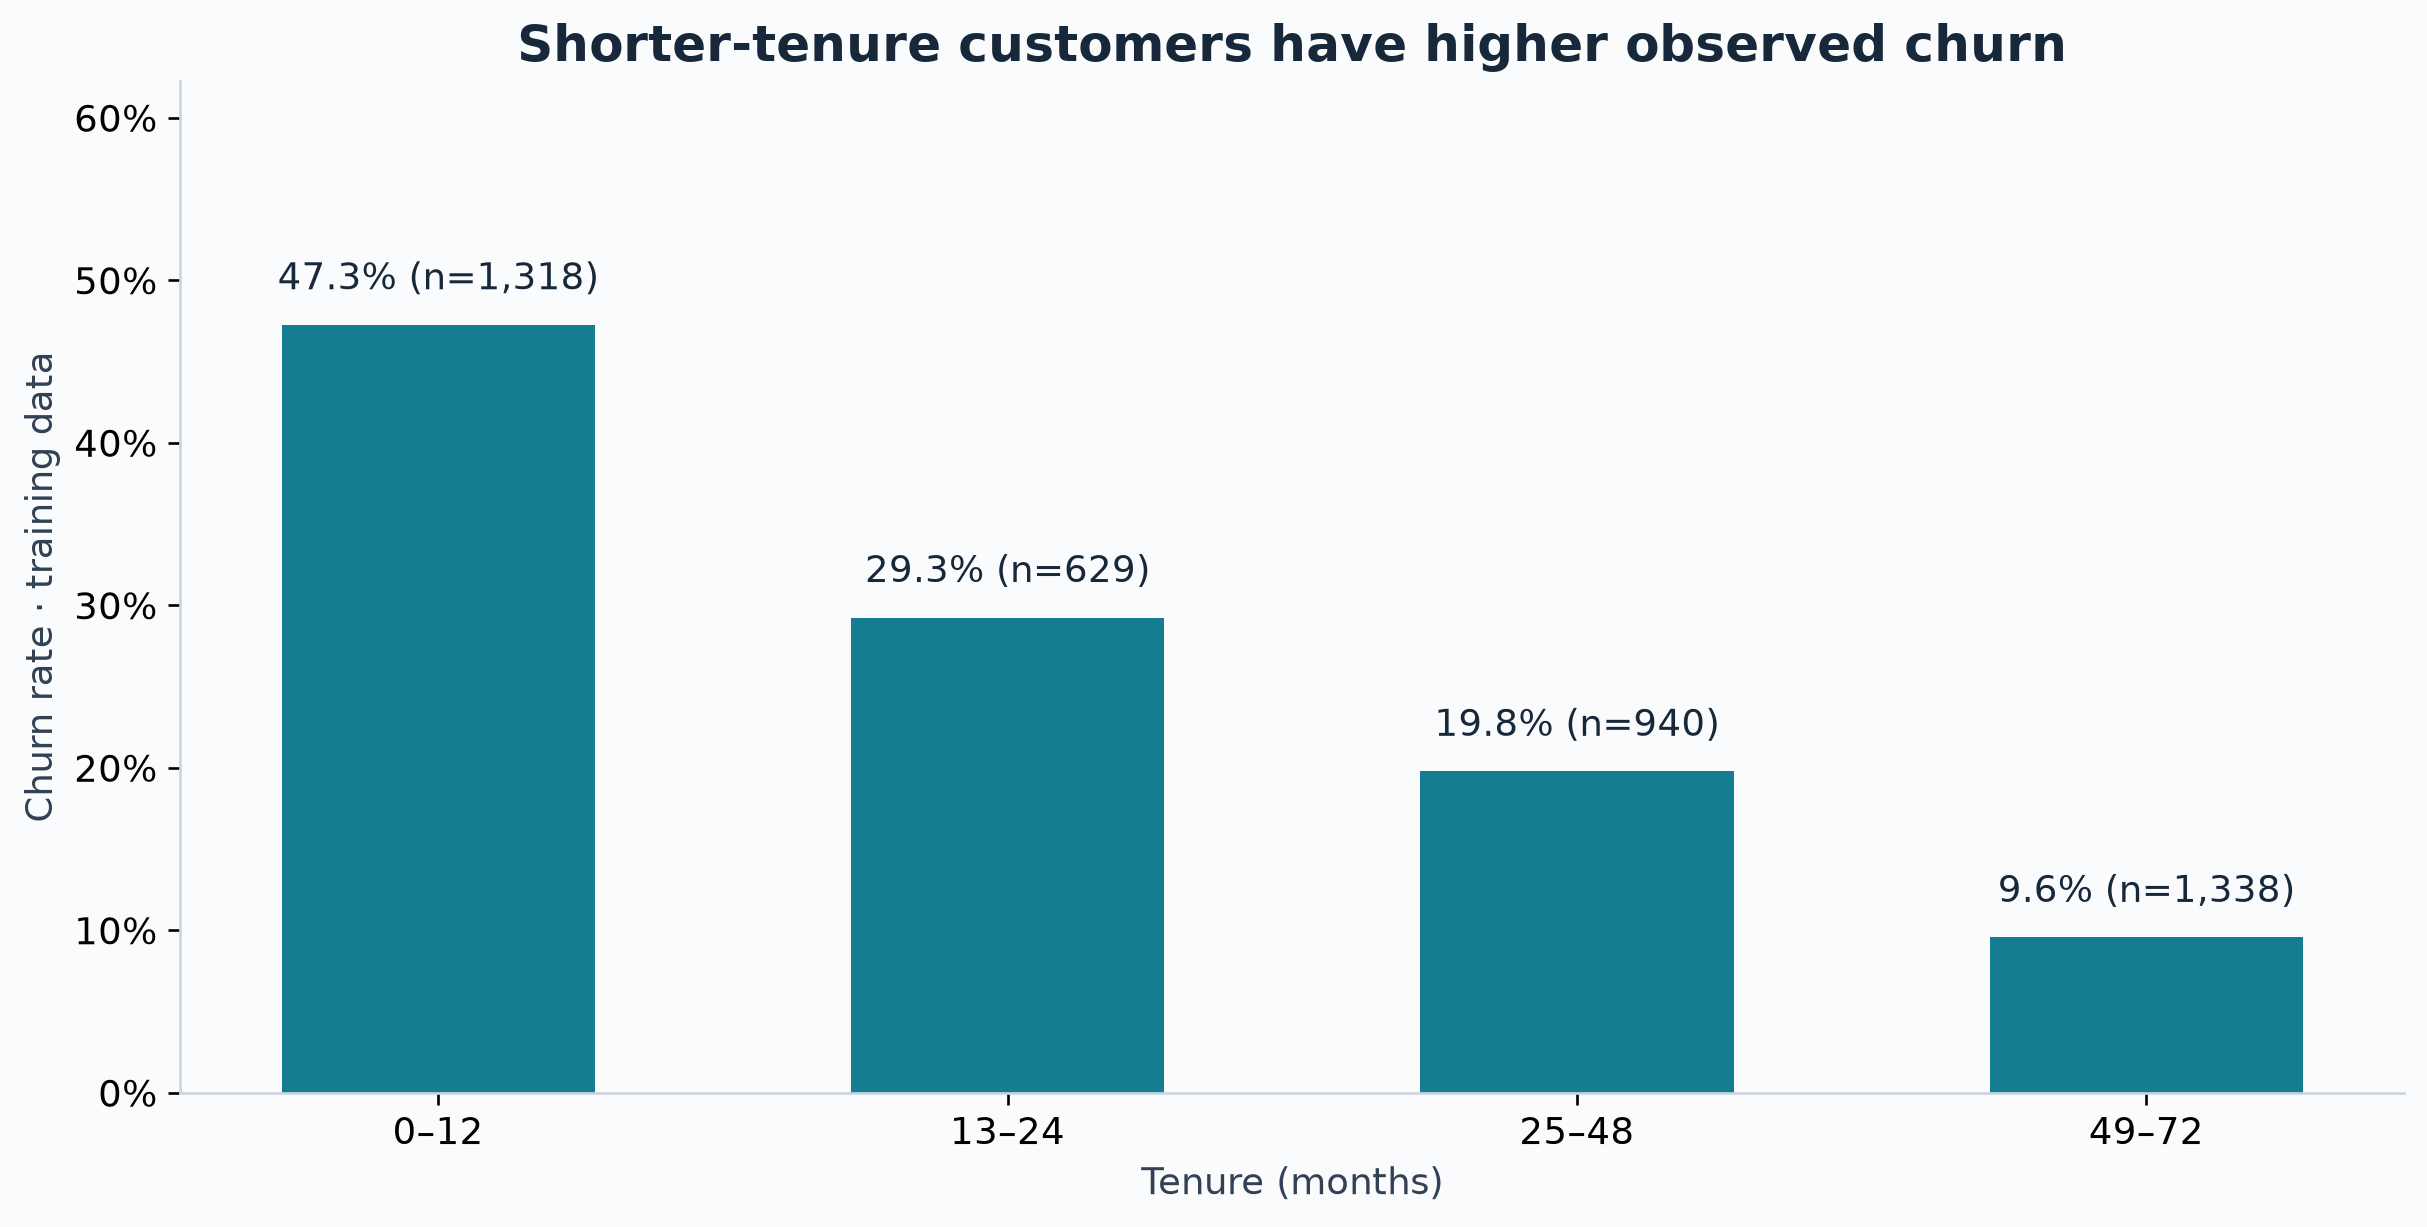

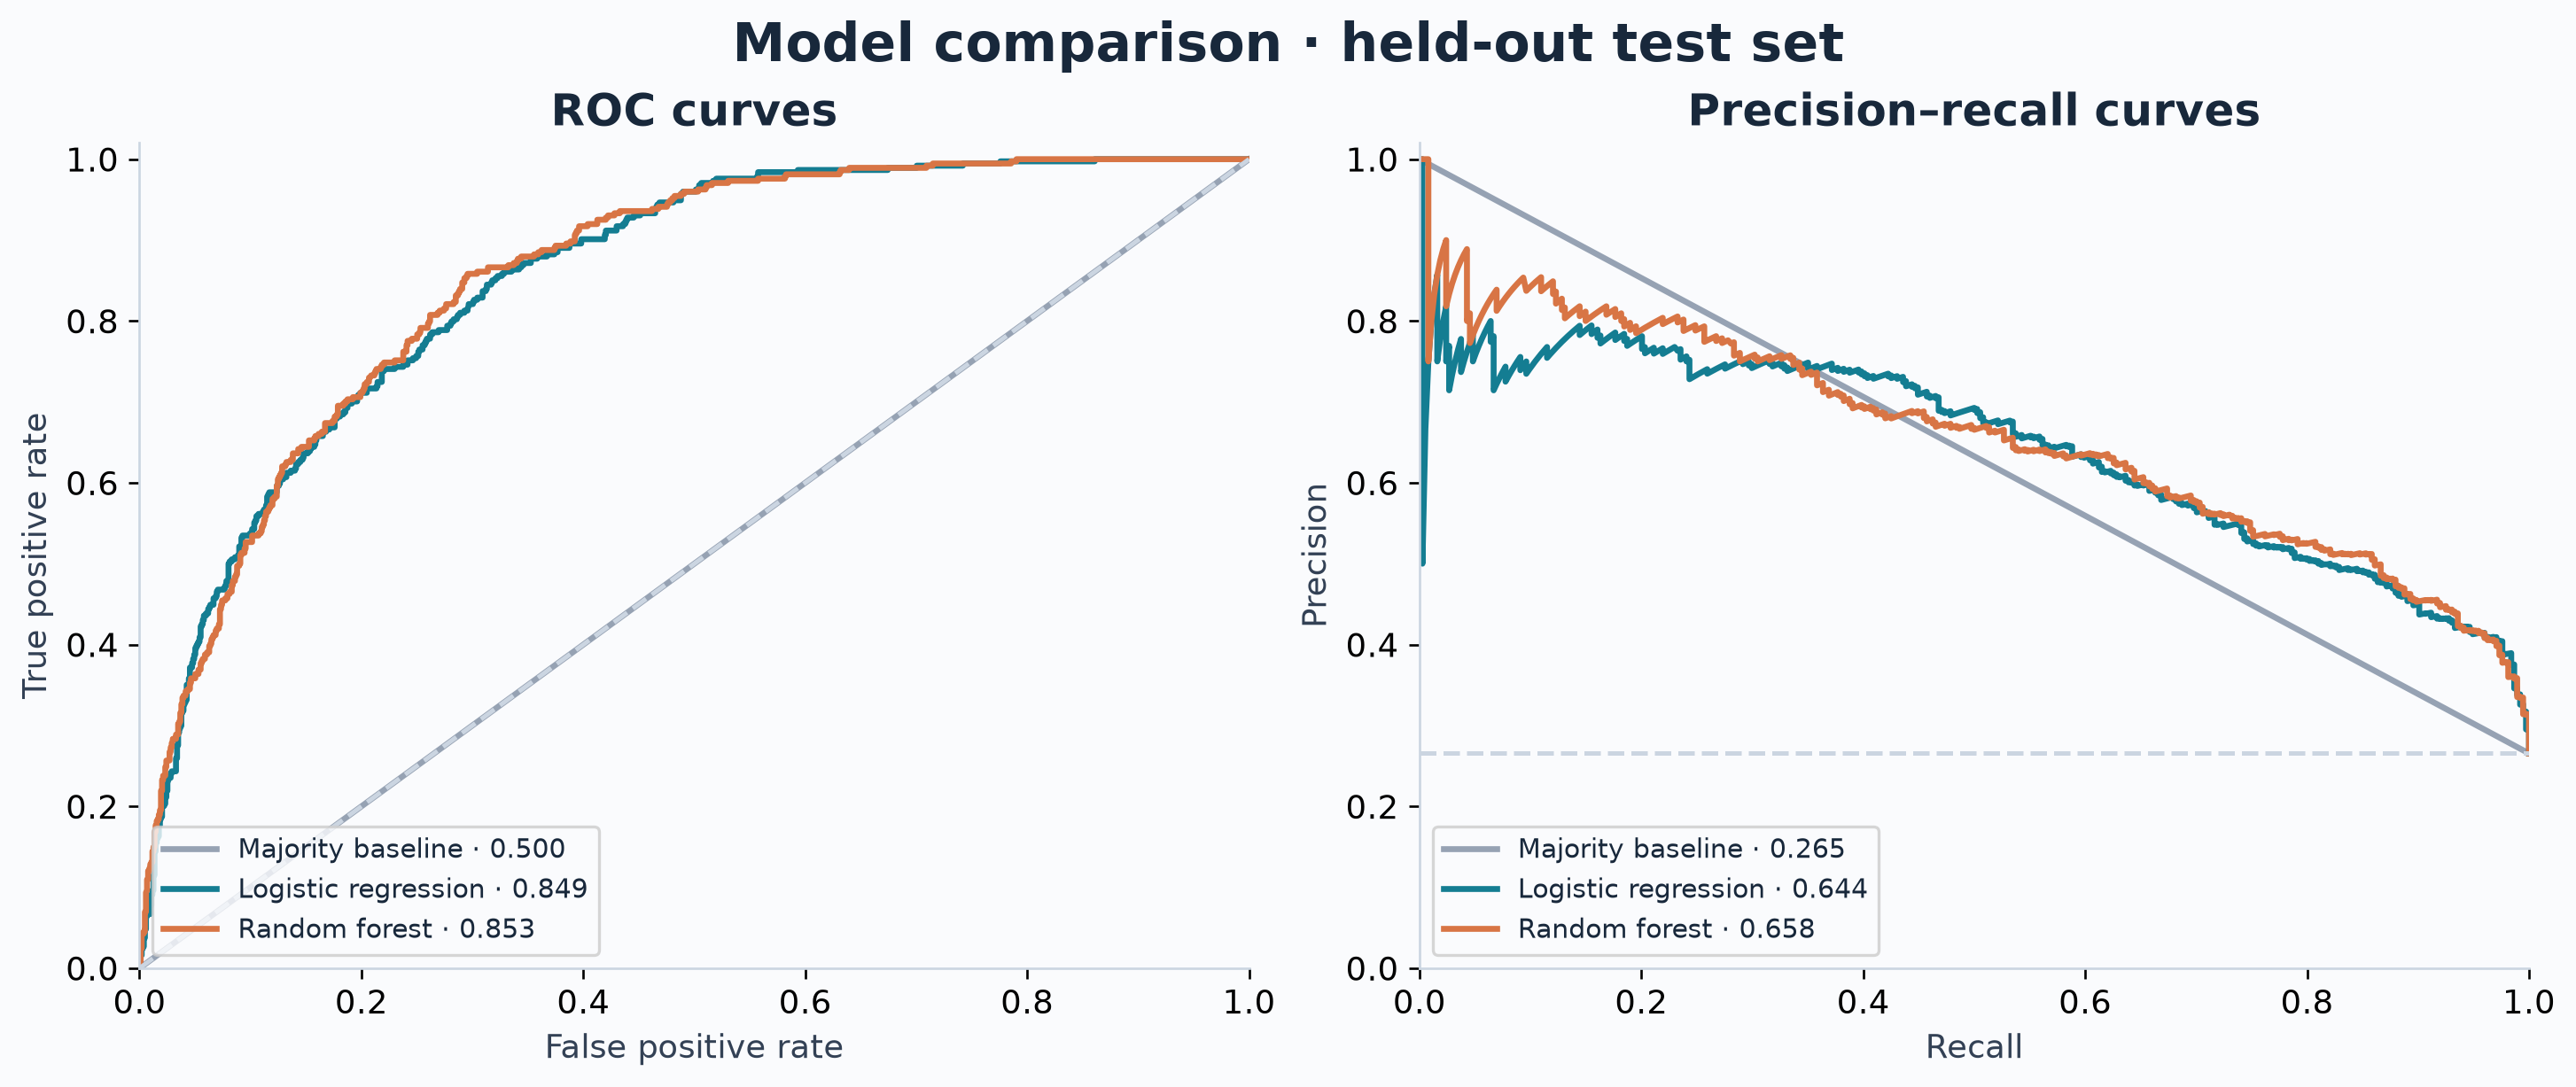

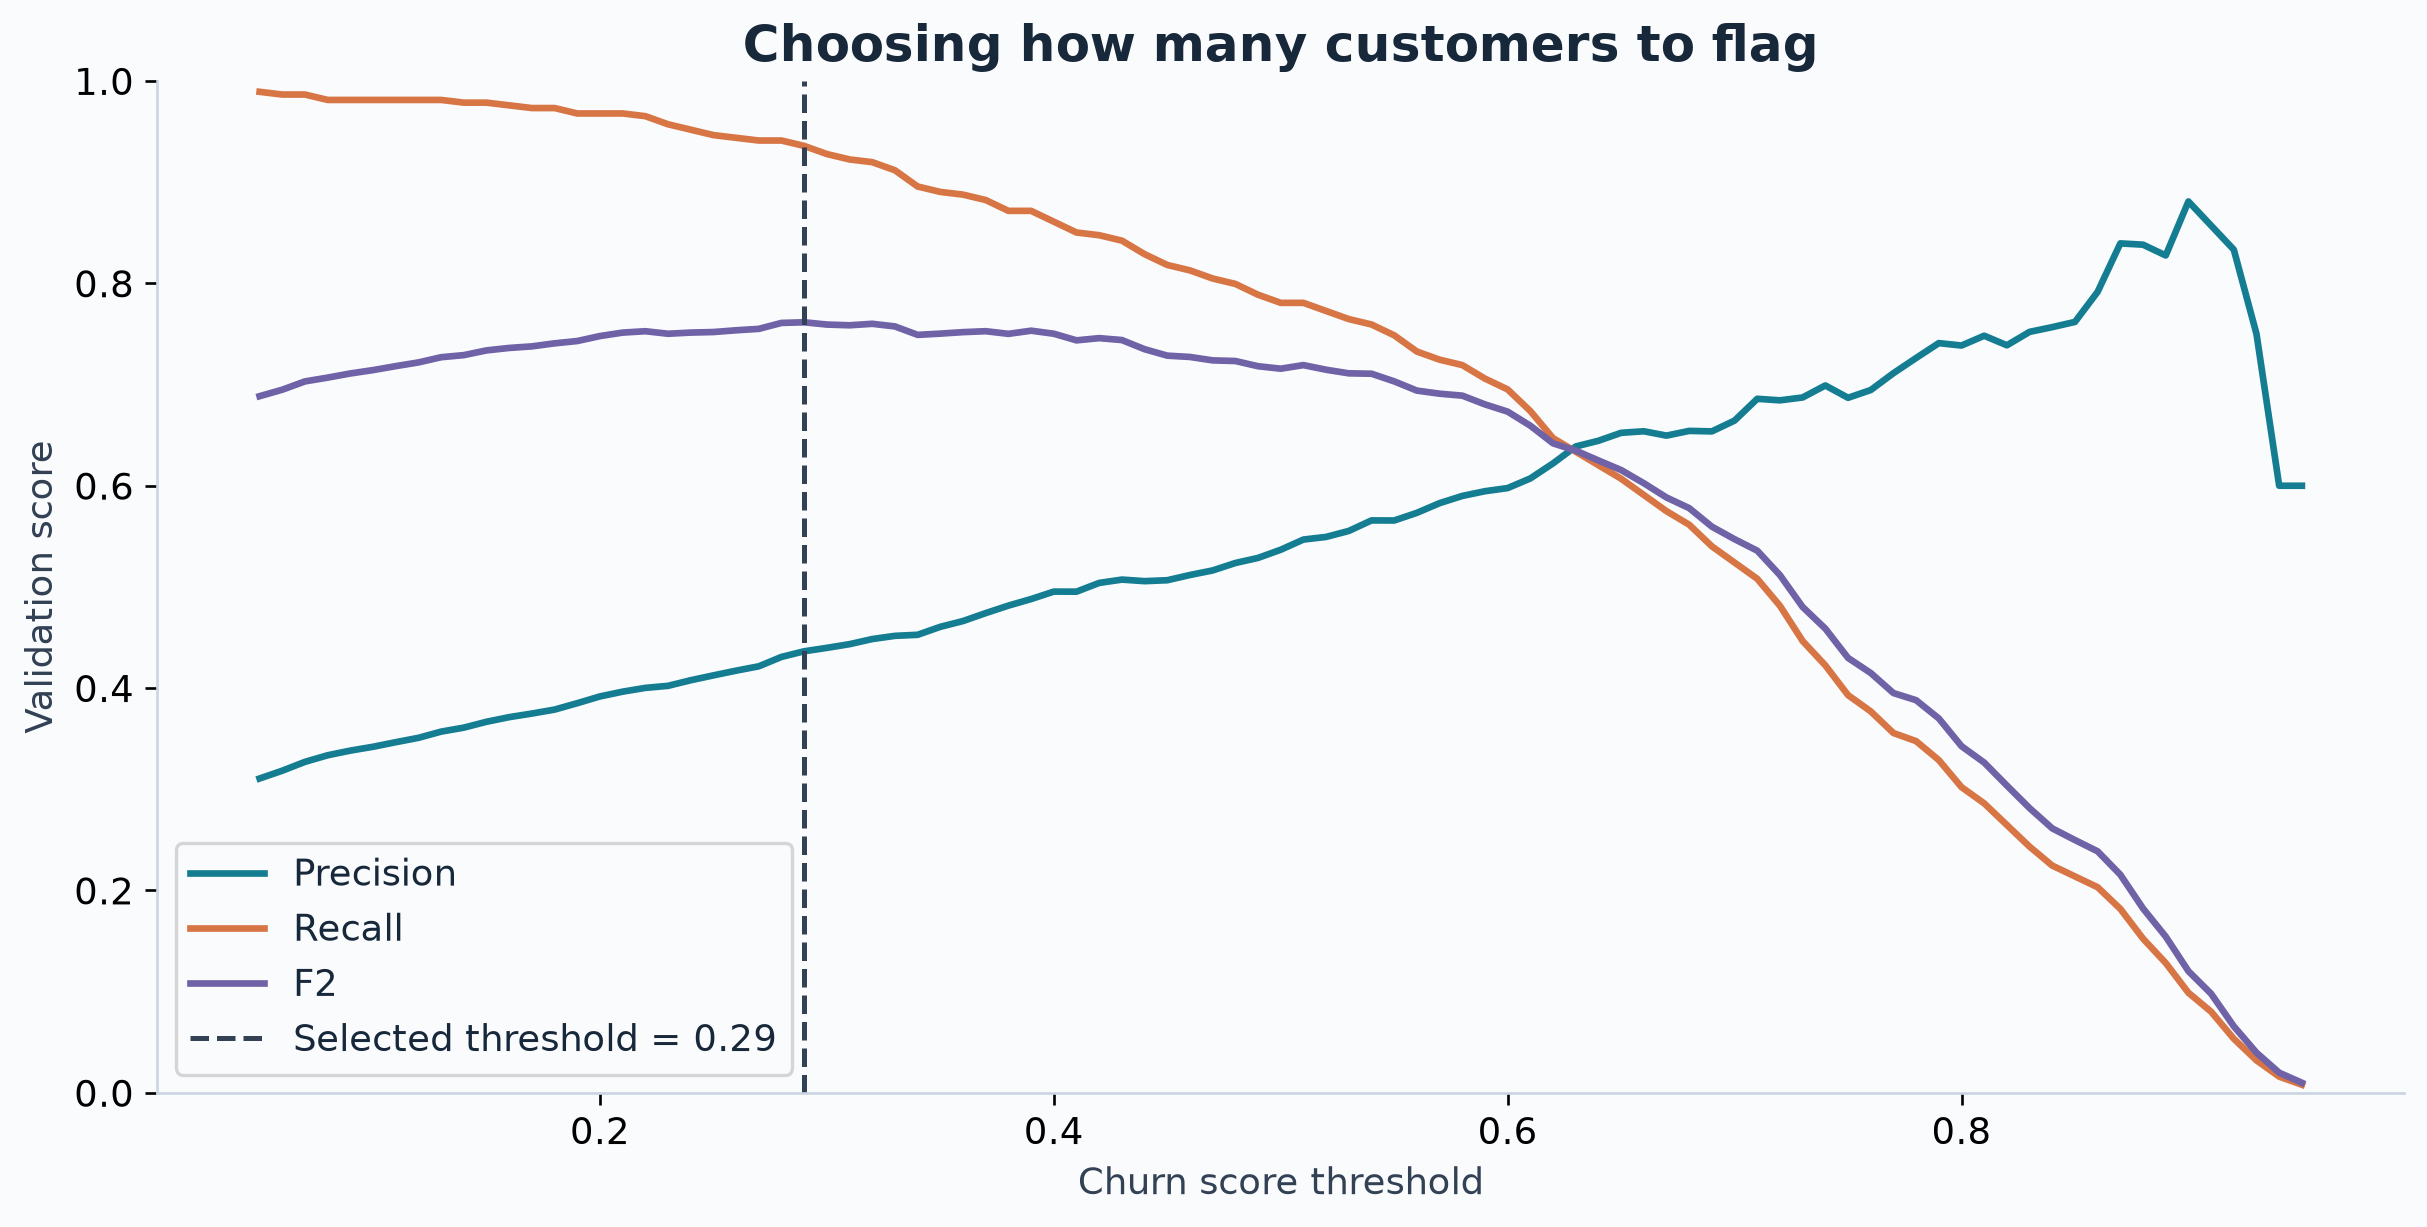

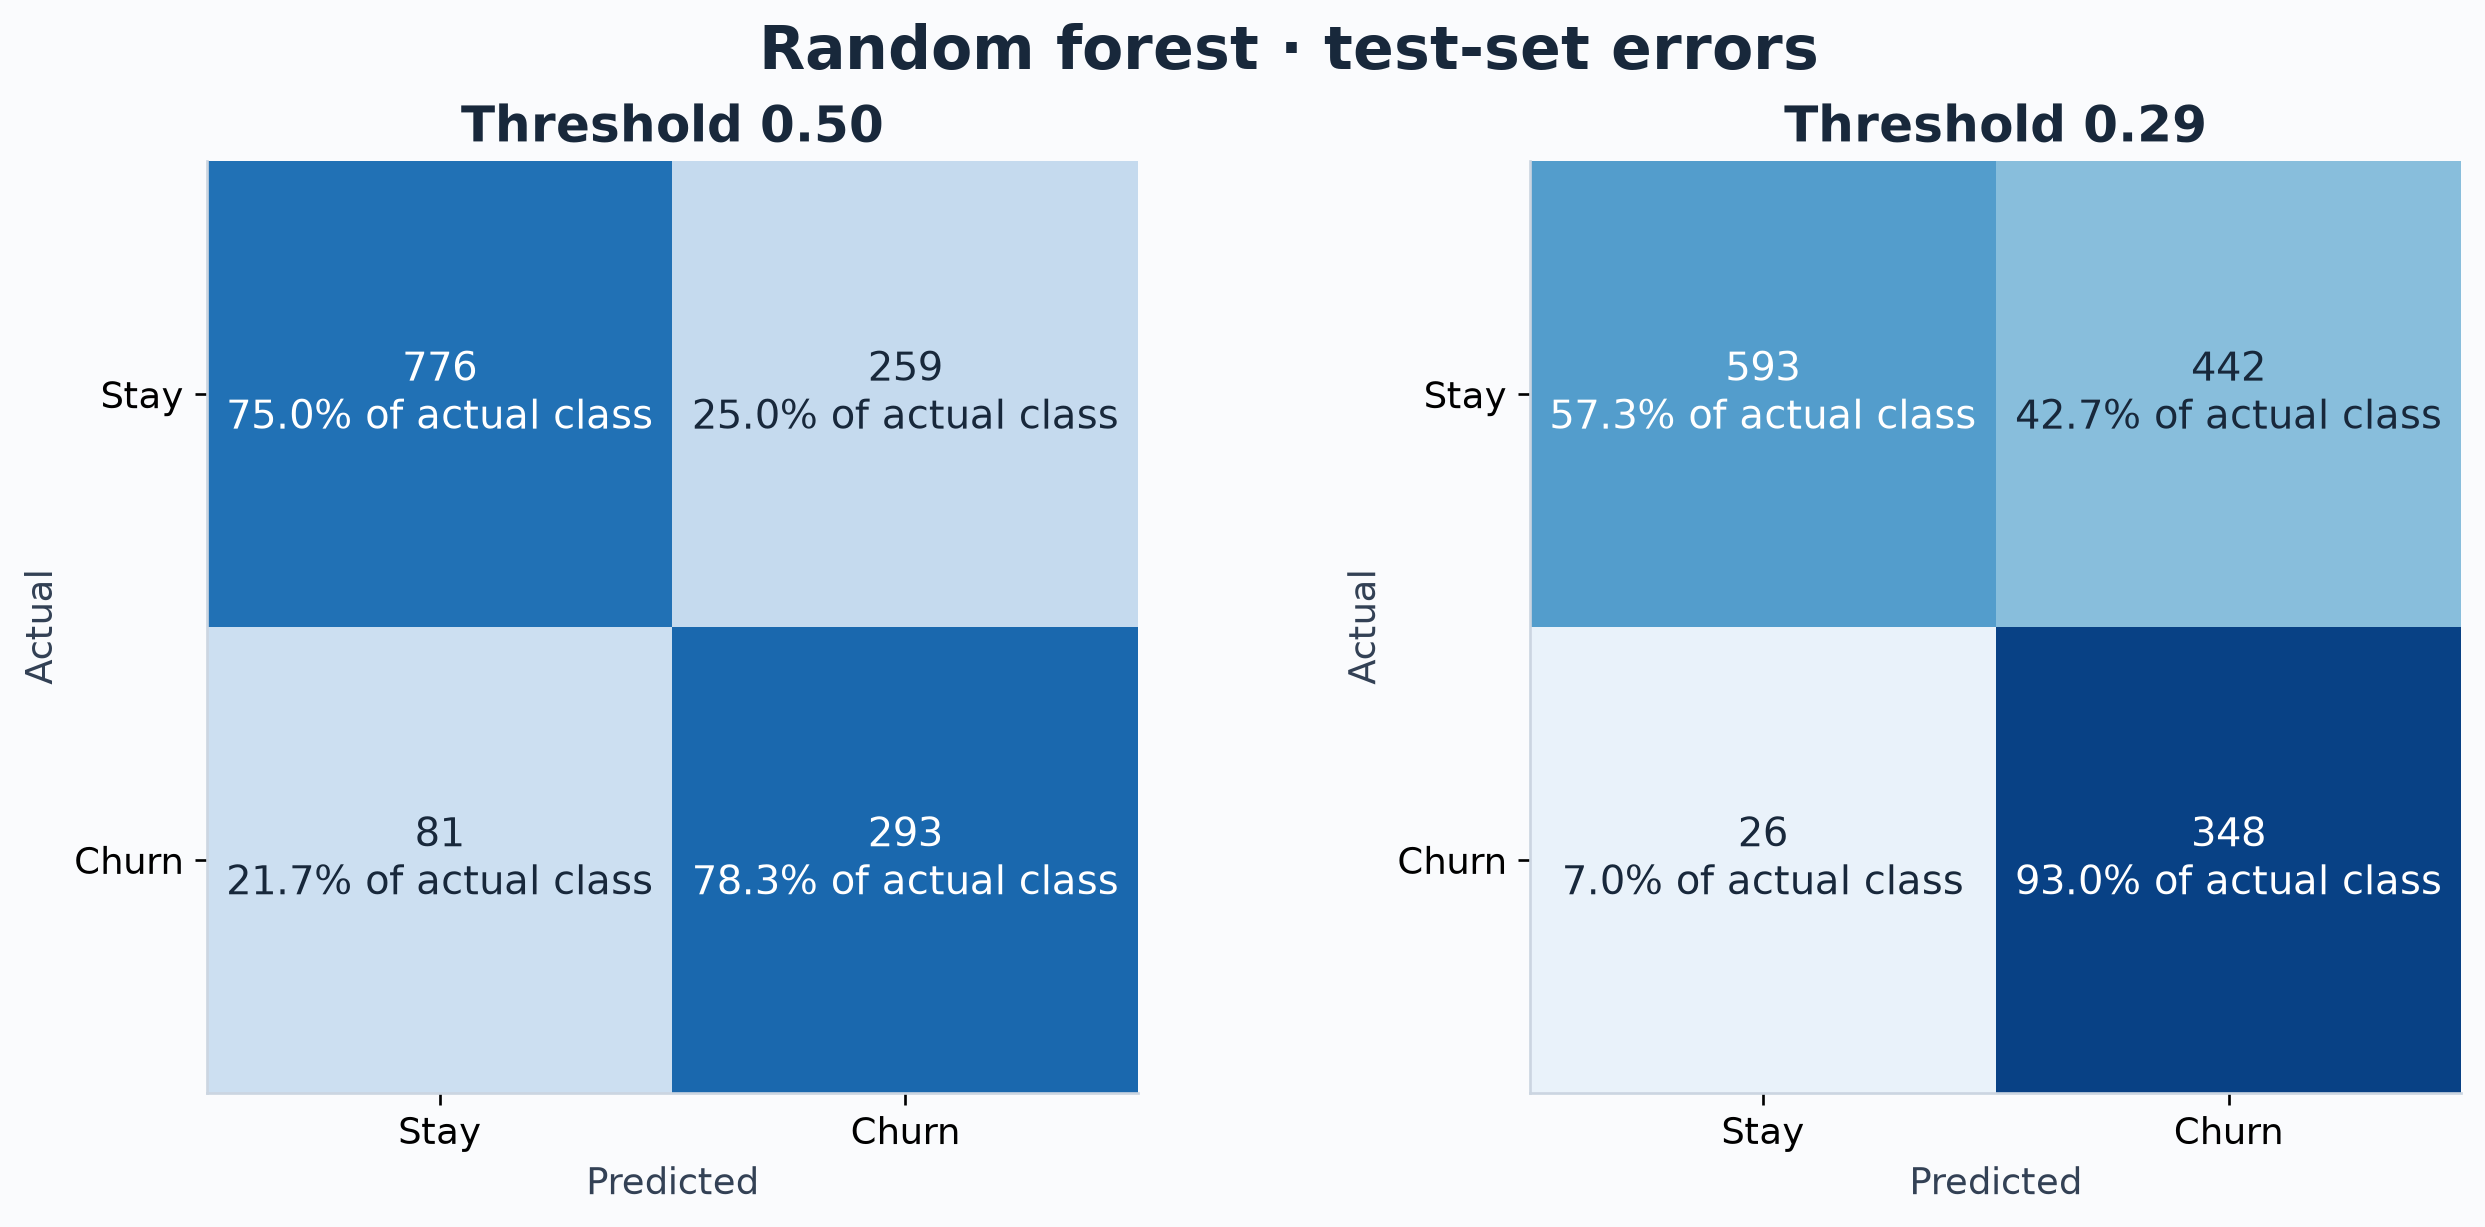

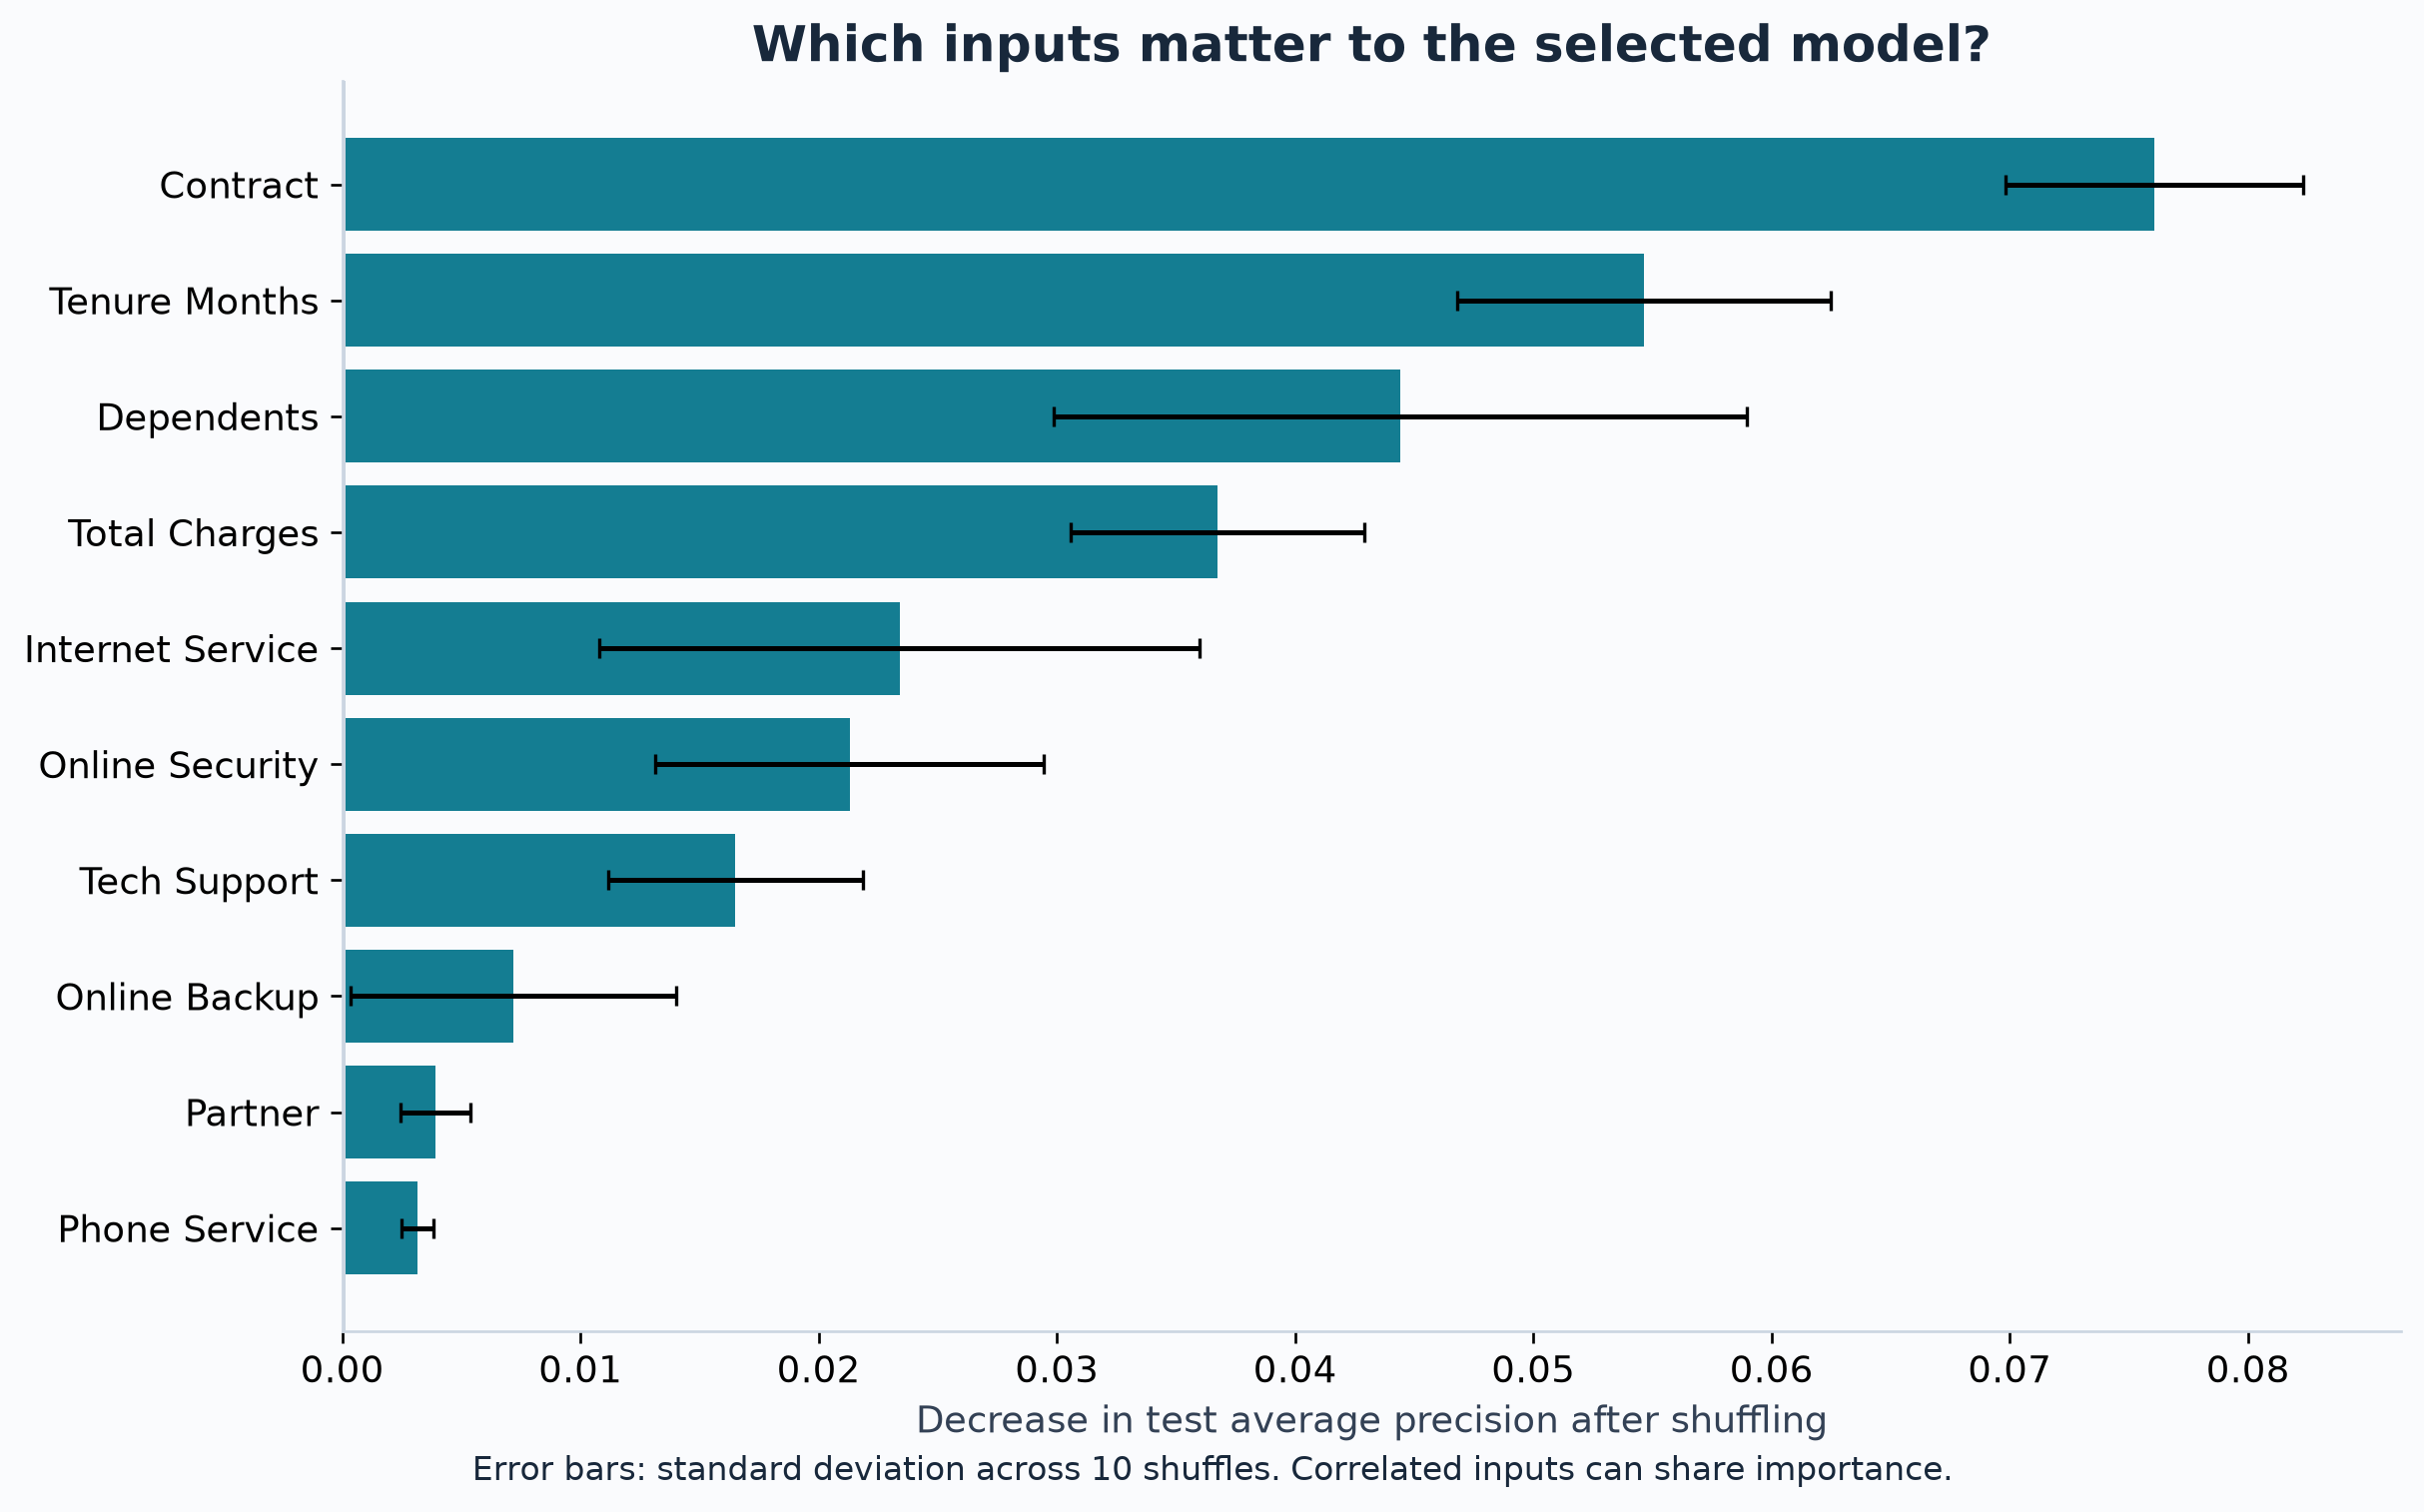

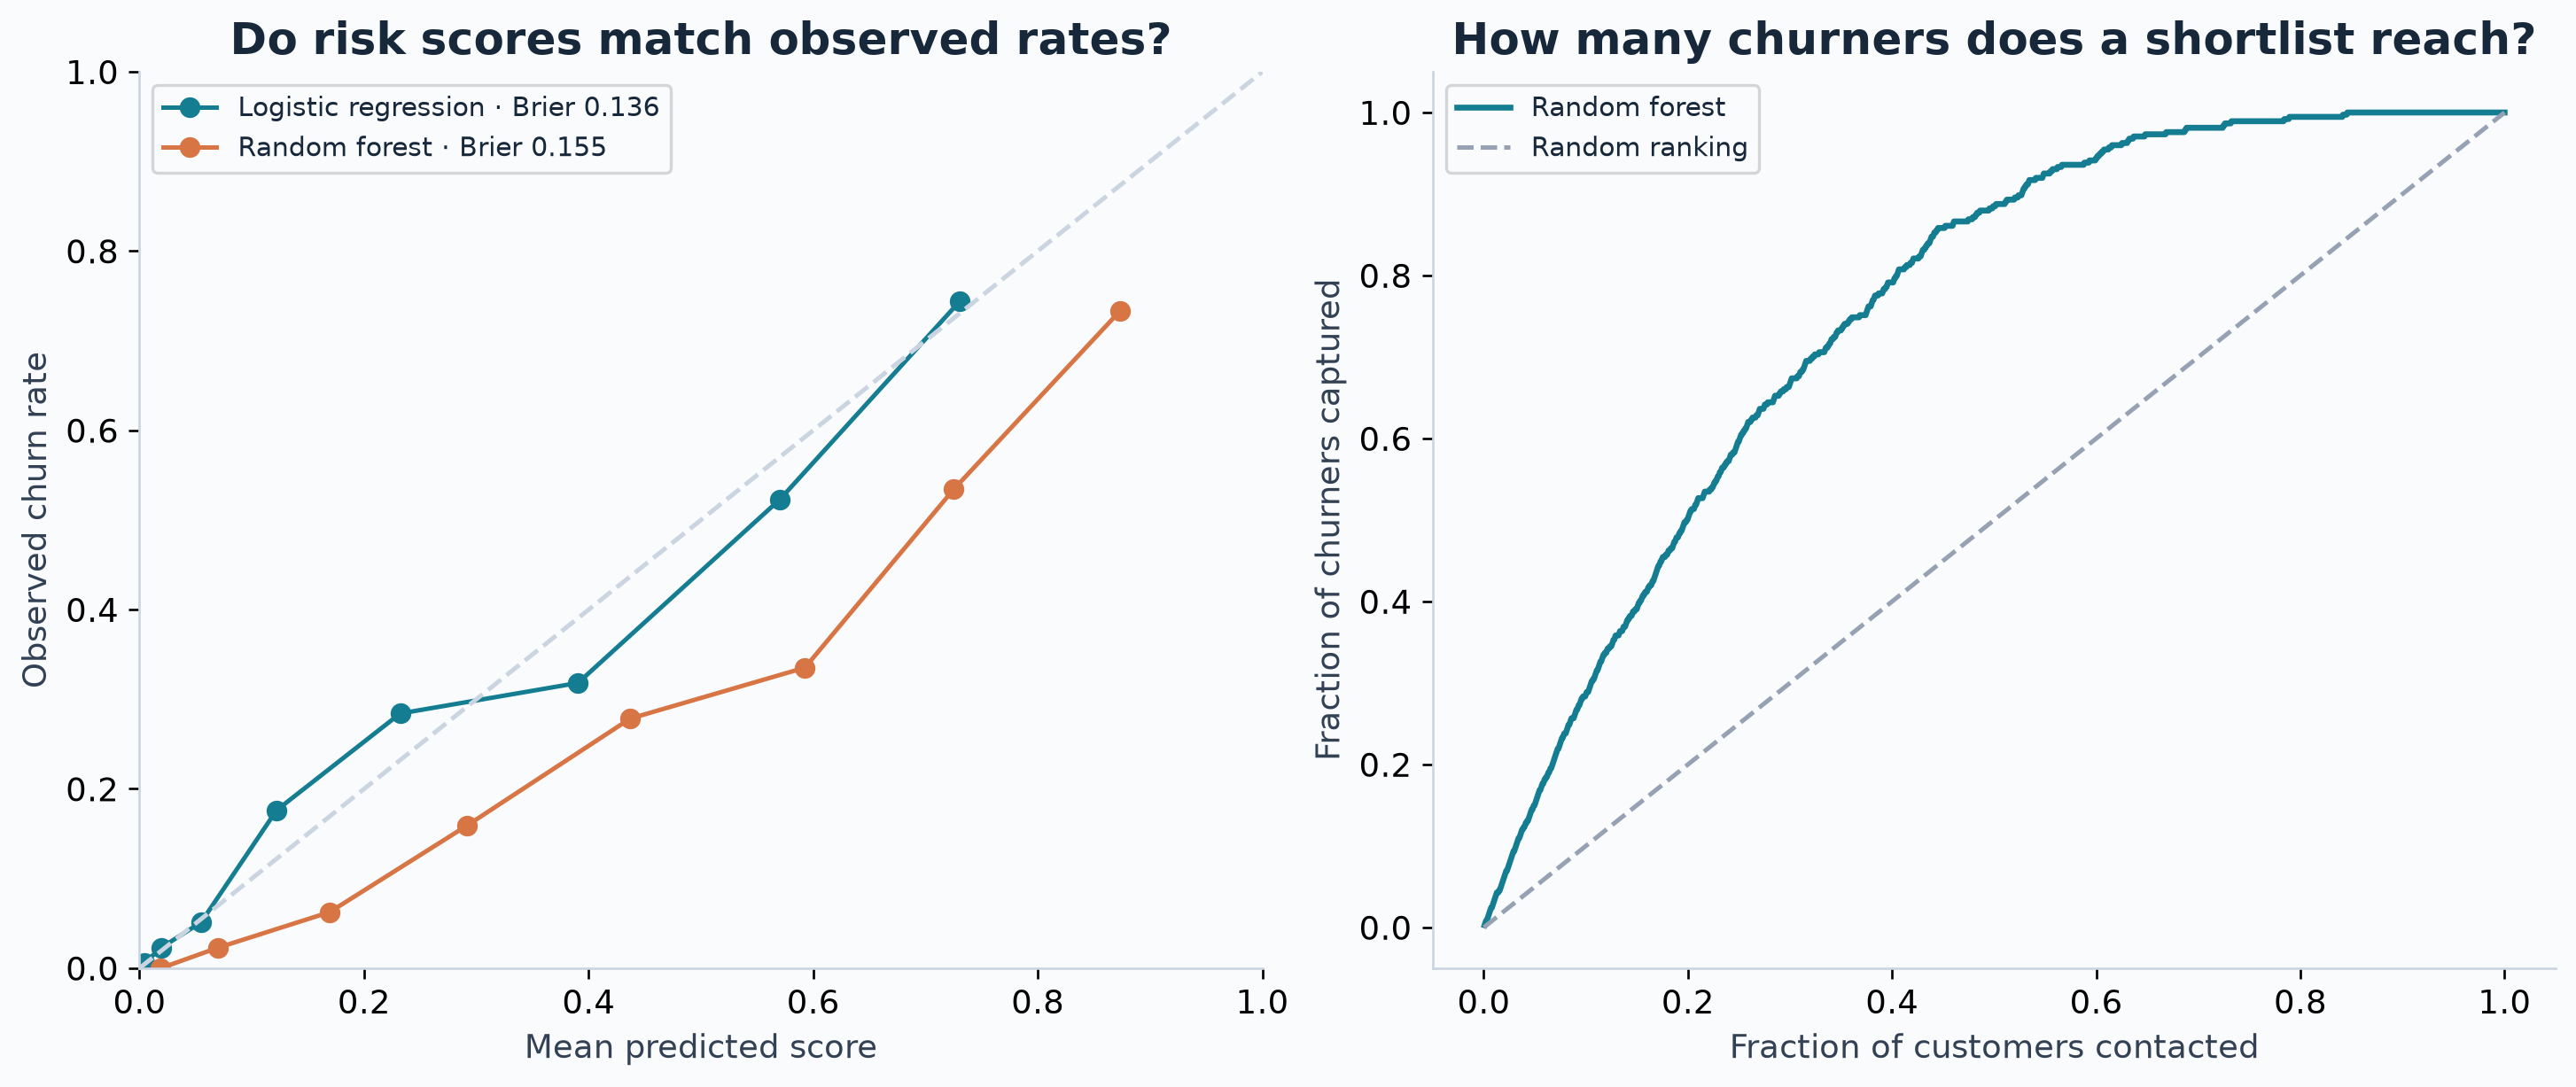

,feature,mean_ap_drop,std_ap_drop
14,Contract,0.0761,0.0062
4,Tenure Months,0.0546,0.0078
3,Dependents,0.0444,0.0146
18,Total Charges,0.0367,0.0062
7,Internet Service,0.0234,0.0126
8,Online Security,0.0213,0.0081
11,Tech Support,0.0165,0.0054
9,Online Backup,0.0072,0.0068
2,Partner,0.0039,0.0015
5,Phone Service,0.0031,0.0007


In [6]:
importance = create_figures(data, splits, models, selected, threshold,
    threshold_results, probabilities, cv_results, ROOT / "figures")
for filename in sorted((ROOT / "figures").glob("*.png")):
    display(Image(filename=str(filename), width=1000))
display(importance.round(4))

## 7. What I take from this experiment

The forest has a small cross-validation ranking advantage over logistic regression. Its test average precision is 0.658. That is useful evidence for this sample, but it does not establish that the more complex model will always win.

The validation-selected threshold catches 93.0% of test churners while flagging 56.1% of all test customers. I would not adopt that workload without knowing the team's capacity and offer costs. A shortlist based on available capacity is another practical option.

Contract and tenure patterns are associations. The model does not show that changing those features causes a customer to stay. The snapshot also lacks dated observations for an advance prediction horizon. My next step with operational data would be a temporal holdout, then an experiment to measure the effect of retention offers.

See `reports/FINDINGS.md` for the write-up and `docs/PROJECT_REVIEW.md` for the changes from the original assignment.